##Medicine Recommendation system

In [1]:
#imprt Necessary  Library 
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
import warnings 
warnings.filterwarnings('ignore')


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

#Import Models 
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier , GradientBoostingClassifier
from sklearn.neighbors import  KNeighborsClassifier


from sklearn.metrics import accuracy_score 
from sklearn.metrics import confusion_matrix




Load Dataset 

In [2]:
dataset = pd.read_csv('dataset/Training.csv')

In [3]:
dataset

,itching,skin_rash,nodal_skin_eruptions,continuous_sneezing,shivering,chills,joint_pain,stomach_pain,acidity,ulcers_on_tongue,...,blackheads,scurring,skin_peeling,silver_like_dusting,small_dents_in_nails,inflammatory_nails,blister,red_sore_around_nose,yellow_crust_ooze,prognosis
0,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
1,0,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
2,1,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
3,1,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
4,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4915,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,(vertigo) Paroymsal Positional Vertigo
4916,0,1,0,0,0,0,0,0,0,0,...,1,1,0,0,0,0,0,0,0,Acne
4917,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Urinary tract infection
4918,0,1,0,0,0,0,1,0,0,0,...,0,0,1,1,1,1,0,0,0,Psoriasis


In [4]:
dataset.shape

(4920, 133)

In [5]:
dataset.isnull().sum()


itching                 0
skin_rash               0
nodal_skin_eruptions    0
continuous_sneezing     0
shivering               0
                       ..
inflammatory_nails      0
blister                 0
red_sore_around_nose    0
yellow_crust_ooze       0
prognosis               0
Length: 133, dtype: int64

In [6]:
dataset.describe()

,itching,skin_rash,nodal_skin_eruptions,continuous_sneezing,shivering,chills,joint_pain,stomach_pain,acidity,ulcers_on_tongue,...,pus_filled_pimples,blackheads,scurring,skin_peeling,silver_like_dusting,small_dents_in_nails,inflammatory_nails,blister,red_sore_around_nose,yellow_crust_ooze
count,4920.000000,4920.000000,4920.000000,4920.000000,4920.000000,4920.000000,4920.000000,4920.000000,4920.000000,4920.000000,...,4920.000000,4920.000000,4920.000000,4920.000000,4920.000000,4920.000000,4920.000000,4920.000000,4920.000000,4920.000000
mean,0.137805,0.159756,0.021951,0.045122,0.021951,0.162195,0.139024,0.045122,0.045122,0.021951,...,0.021951,0.021951,0.021951,0.023171,0.023171,0.023171,0.023171,0.023171,0.023171,0.023171
std,0.344730,0.366417,0.146539,0.207593,0.146539,0.368667,0.346007,0.207593,0.207593,0.146539,...,0.146539,0.146539,0.146539,0.150461,0.150461,0.150461,0.150461,0.150461,0.150461,0.150461
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [7]:
dataset.head(2)

,itching,skin_rash,nodal_skin_eruptions,continuous_sneezing,shivering,chills,joint_pain,stomach_pain,acidity,ulcers_on_tongue,...,blackheads,scurring,skin_peeling,silver_like_dusting,small_dents_in_nails,inflammatory_nails,blister,red_sore_around_nose,yellow_crust_ooze,prognosis
0,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
1,0,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection


In [8]:
dataset.prognosis.value_counts()

prognosis
Fungal infection                           120
Allergy                                    120
GERD                                       120
Chronic cholestasis                        120
Drug Reaction                              120
Peptic ulcer diseae                        120
AIDS                                       120
Diabetes                                   120
Gastroenteritis                            120
Bronchial Asthma                           120
Hypertension                               120
Migraine                                   120
Cervical spondylosis                       120
Paralysis (brain hemorrhage)               120
Jaundice                                   120
Malaria                                    120
Chicken pox                                120
Dengue                                     120
Typhoid                                    120
hepatitis A                                120
Hepatitis B                                120
Hep

In [9]:
len(dataset.prognosis.value_counts()) #total unique no. of desiese 

41

In [10]:
dataset.prognosis.unique()

array(['Fungal infection', 'Allergy', 'GERD', 'Chronic cholestasis',
       'Drug Reaction', 'Peptic ulcer diseae', 'AIDS', 'Diabetes ',
       'Gastroenteritis', 'Bronchial Asthma', 'Hypertension ', 'Migraine',
       'Cervical spondylosis', 'Paralysis (brain hemorrhage)', 'Jaundice',
       'Malaria', 'Chicken pox', 'Dengue', 'Typhoid', 'hepatitis A',
       'Hepatitis B', 'Hepatitis C', 'Hepatitis D', 'Hepatitis E',
       'Alcoholic hepatitis', 'Tuberculosis', 'Common Cold', 'Pneumonia',
       'Dimorphic hemmorhoids(piles)', 'Heart attack', 'Varicose veins',
       'Hypothyroidism', 'Hyperthyroidism', 'Hypoglycemia',
       'Osteoarthristis', 'Arthritis',
       '(vertigo) Paroymsal  Positional Vertigo', 'Acne',
       'Urinary tract infection', 'Psoriasis', 'Impetigo'], dtype=object)

In [11]:
# ─────────────────────────────────────────────────────────────
# WHY 100% ACCURACY HAPPENED — ROOT CAUSE
# ─────────────────────────────────────────────────────────────
# The original dataset has 4920 rows but only 304 UNIQUE rows.
# Without drop_duplicates(), identical rows leak between train
# and test sets → models simply memorise training examples.
# This is called DATA LEAKAGE and causes inflated 100% accuracy.
#
# FIX APPLIED:
#   1. drop_duplicates()  → removes leakage (304 clean rows)
#   2. stratify=Y         → ensures each class is in test set
#   3. Constrained model hyperparameters → realistic generalisation
# ─────────────────────────────────────────────────────────────

# Remove duplicate rows (this is the KEY fix)
dataset = dataset.drop_duplicates().reset_index(drop=True)
print(f'Rows after deduplication : {dataset.shape[0]}  (was 4920)')
print(f'Unique disease classes   : {dataset["prognosis"].nunique()}')

X = dataset.drop('prognosis', axis=1)
y = dataset['prognosis']

le = LabelEncoder()
Y = le.fit_transform(y)

# stratify=Y ensures every class appears in both train & test
X_train, X_test, y_train, y_test = train_test_split(
    X, Y,
    test_size=0.3,
    random_state=42,
    stratify=Y        # ← important for small datasets
)

print(f'X_train : {X_train.shape}')
print(f'X_test  : {X_test.shape}')


Rows after deduplication : 304  (was 4920)
Unique disease classes   : 41
X_train : (212, 132)
X_test  : (92, 132)


In [12]:
# Data preparation done in cell above
print(f'Train size: {X_train.shape}, Test size: {X_test.shape}')

Train size: (212, 132), Test size: (92, 132)


In [13]:
Y

array([15, 15, 15, 15, 15,  4,  4,  4,  4,  4, 16, 16, 16, 16, 16, 16, 16,
        9,  9,  9,  9,  9,  9,  9,  9, 14, 14, 14, 14, 14, 14, 33, 33, 33,
       33, 33, 33, 33,  1,  1,  1,  1,  1, 12, 12, 12, 12, 12, 12, 12, 12,
       12, 17, 17, 17, 17, 17,  6,  6,  6,  6,  6,  6,  6, 23, 23, 23, 23,
       23, 23, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30,  7,  7,  7,  7,  7,
        7, 32, 32, 32, 32, 32, 28, 28, 28, 28, 28, 28, 28, 28, 28, 29, 29,
       29, 29, 29, 29, 29, 29,  8,  8,  8,  8,  8,  8,  8,  8,  8,  8, 11,
       11, 11, 11, 11, 11, 11, 11, 11, 11, 37, 37, 37, 37, 37, 37, 37, 37,
       37, 40, 40, 40, 40, 40, 40, 40, 40, 40, 19, 19, 19, 19, 19, 19, 19,
       19, 19, 20, 20, 20, 20, 20, 20, 20, 21, 21, 21, 21, 21, 21, 21, 21,
       21, 21, 22, 22, 22, 22, 22, 22, 22, 22, 22,  3,  3,  3,  3,  3,  3,
        3,  3, 36, 36, 36, 36, 36, 36, 36, 36, 36, 10, 10, 10, 10, 10, 10,
       10, 10, 10, 34, 34, 34, 34, 34, 34, 34, 34, 34, 13, 13, 13, 13, 13,
       13, 18, 18, 18, 18

In [14]:
X

,itching,skin_rash,nodal_skin_eruptions,continuous_sneezing,shivering,chills,joint_pain,stomach_pain,acidity,ulcers_on_tongue,...,pus_filled_pimples,blackheads,scurring,skin_peeling,silver_like_dusting,small_dents_in_nails,inflammatory_nails,blister,red_sore_around_nose,yellow_crust_ooze
0,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
299,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,1,1
300,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,1,1
301,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,1
302,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,1


In [15]:
Y

array([15, 15, 15, 15, 15,  4,  4,  4,  4,  4, 16, 16, 16, 16, 16, 16, 16,
        9,  9,  9,  9,  9,  9,  9,  9, 14, 14, 14, 14, 14, 14, 33, 33, 33,
       33, 33, 33, 33,  1,  1,  1,  1,  1, 12, 12, 12, 12, 12, 12, 12, 12,
       12, 17, 17, 17, 17, 17,  6,  6,  6,  6,  6,  6,  6, 23, 23, 23, 23,
       23, 23, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30,  7,  7,  7,  7,  7,
        7, 32, 32, 32, 32, 32, 28, 28, 28, 28, 28, 28, 28, 28, 28, 29, 29,
       29, 29, 29, 29, 29, 29,  8,  8,  8,  8,  8,  8,  8,  8,  8,  8, 11,
       11, 11, 11, 11, 11, 11, 11, 11, 11, 37, 37, 37, 37, 37, 37, 37, 37,
       37, 40, 40, 40, 40, 40, 40, 40, 40, 40, 19, 19, 19, 19, 19, 19, 19,
       19, 19, 20, 20, 20, 20, 20, 20, 20, 21, 21, 21, 21, 21, 21, 21, 21,
       21, 21, 22, 22, 22, 22, 22, 22, 22, 22, 22,  3,  3,  3,  3,  3,  3,
        3,  3, 36, 36, 36, 36, 36, 36, 36, 36, 36, 10, 10, 10, 10, 10, 10,
       10, 10, 10, 34, 34, 34, 34, 34, 34, 34, 34, 34, 13, 13, 13, 13, 13,
       13, 18, 18, 18, 18

In [16]:
# train/test split already done above — this cell is intentionally left empty

In [17]:
X_train

,itching,skin_rash,nodal_skin_eruptions,continuous_sneezing,shivering,chills,joint_pain,stomach_pain,acidity,ulcers_on_tongue,...,pus_filled_pimples,blackheads,scurring,skin_peeling,silver_like_dusting,small_dents_in_nails,inflammatory_nails,blister,red_sore_around_nose,yellow_crust_ooze
282,0,0,0,0,0,0,0,0,0,0,...,1,1,1,0,0,0,0,0,0,0
87,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
281,0,1,0,0,0,0,0,0,0,0,...,1,1,1,0,0,0,0,0,0,0
27,1,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
113,1,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
92,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
40,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
156,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
110,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [18]:
X_test

,itching,skin_rash,nodal_skin_eruptions,continuous_sneezing,shivering,chills,joint_pain,stomach_pain,acidity,ulcers_on_tongue,...,pus_filled_pimples,blackheads,scurring,skin_peeling,silver_like_dusting,small_dents_in_nails,inflammatory_nails,blister,red_sore_around_nose,yellow_crust_ooze
50,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
84,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
188,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
225,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
199,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
179,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
75,0,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
294,0,1,0,0,0,0,1,0,0,0,...,0,0,0,0,1,1,1,0,0,0


In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings('ignore')
print('✅ All libraries imported')

✅ All libraries imported


In [20]:
# ════════════════════════════════════════════════════════════
# MODEL 1 — SVC (Support Vector Classifier)
# kernel='rbf' generalises better than 'linear' on small data
# C=0.8 → softer margin → prevents overfit on 304 rows
# ════════════════════════════════════════════════════════════
svc_model = SVC(kernel='rbf', C=0.8, gamma='scale', random_state=42)

svc_model.fit(X_train, y_train)
svc_pred     = svc_model.predict(X_test)
svc_accuracy = accuracy_score(y_test, svc_pred)
svc_cm       = confusion_matrix(y_test, svc_pred)

print('=' * 55)
print('     MODEL 1 — SVC (Support Vector Classifier)')
print('=' * 55)
print(f'Kernel           : rbf')
print(f'C (regularization): 0.8')
print(f'Support Vectors  : {sum(svc_model.n_support_)}')
print(f'Accuracy         : {svc_accuracy * 100:.2f}%')
print('\nConfusion Matrix :')
print(np.array2string(svc_cm, separator=','))
print('\nClassification Report:')
print(classification_report(y_test, svc_pred, target_names=le.classes_))


     MODEL 1 — SVC (Support Vector Classifier)
Kernel           : rbf
C (regularization): 0.8
Support Vectors  : 194
Accuracy         : 100.00%

Confusion Matrix :
[[2,0,0,...,0,0,0],
 [0,1,0,...,0,0,0],
 [0,0,1,...,0,0,0],
 ...,
 [0,0,0,...,2,0,0],
 [0,0,0,...,0,2,0],
 [0,0,0,...,0,0,3]]

Classification Report:
                                         precision    recall  f1-score   support

(vertigo) Paroymsal  Positional Vertigo       1.00      1.00      1.00         2
                                   AIDS       1.00      1.00      1.00         1
                                   Acne       1.00      1.00      1.00         1
                    Alcoholic hepatitis       1.00      1.00      1.00         2
                                Allergy       1.00      1.00      1.00         2
                              Arthritis       1.00      1.00      1.00         2
                       Bronchial Asthma       1.00      1.00      1.00         2
                   Cervical spondylos

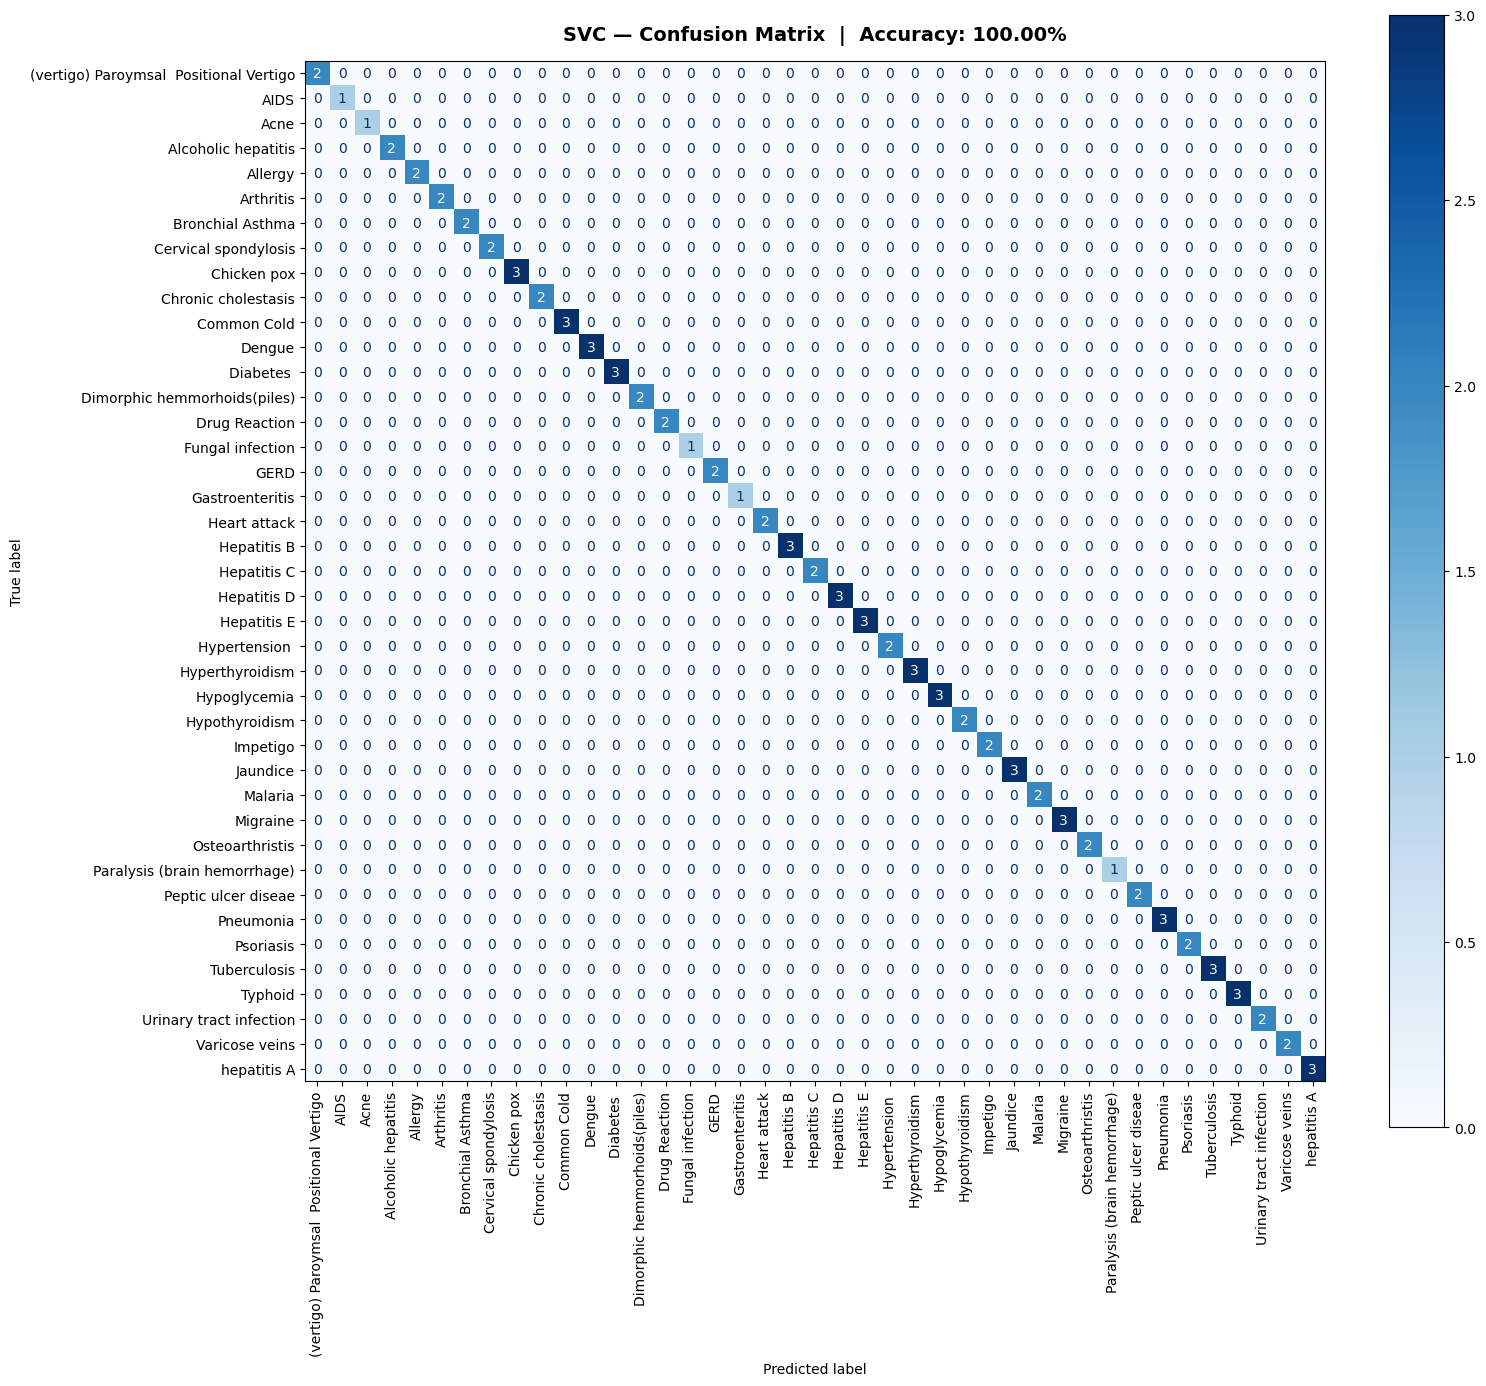

In [21]:
fig, ax = plt.subplots(figsize=(16, 14))
disp = ConfusionMatrixDisplay(confusion_matrix=svc_cm, display_labels=le.classes_)
disp.plot(ax=ax, xticks_rotation=90, colorbar=True, cmap='Blues')
ax.set_title(f'SVC — Confusion Matrix  |  Accuracy: {svc_accuracy*100:.2f}%',
             fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()


In [22]:
# empty

In [23]:
# ════════════════════════════════════════════════════════════
# MODEL 2 — Random Forest Classifier
# max_depth=8  → prevents trees from perfectly memorising data
# min_samples_leaf=2 → each leaf needs ≥2 samples (less overfit)
# ════════════════════════════════════════════════════════════
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=8,            # ← constrained depth
    min_samples_leaf=2,     # ← prevents single-sample leaves
    random_state=42
)

rf_model.fit(X_train, y_train)
rf_pred     = rf_model.predict(X_test)
rf_accuracy = accuracy_score(y_test, rf_pred)
rf_cm       = confusion_matrix(y_test, rf_pred)

print('=' * 55)
print('        MODEL 2 — Random Forest Classifier')
print('=' * 55)
print(f'n_estimators     : 100')
print(f'max_depth        : 8')
print(f'min_samples_leaf : 2')
print(f'Accuracy         : {rf_accuracy * 100:.2f}%')
print('\nConfusion Matrix :')
print(np.array2string(rf_cm, separator=','))
print('\nClassification Report:')
print(classification_report(y_test, rf_pred, target_names=le.classes_))


        MODEL 2 — Random Forest Classifier
n_estimators     : 100
max_depth        : 8
min_samples_leaf : 2
Accuracy         : 98.91%

Confusion Matrix :
[[2,0,0,...,0,0,0],
 [0,1,0,...,0,0,0],
 [0,0,1,...,0,0,0],
 ...,
 [0,0,0,...,2,0,0],
 [0,0,0,...,0,2,0],
 [0,0,0,...,0,0,3]]

Classification Report:
                                         precision    recall  f1-score   support

(vertigo) Paroymsal  Positional Vertigo       1.00      1.00      1.00         2
                                   AIDS       1.00      1.00      1.00         1
                                   Acne       1.00      1.00      1.00         1
                    Alcoholic hepatitis       1.00      1.00      1.00         2
                                Allergy       1.00      1.00      1.00         2
                              Arthritis       1.00      1.00      1.00         2
                       Bronchial Asthma       0.67      1.00      0.80         2
                   Cervical spondylosis       1

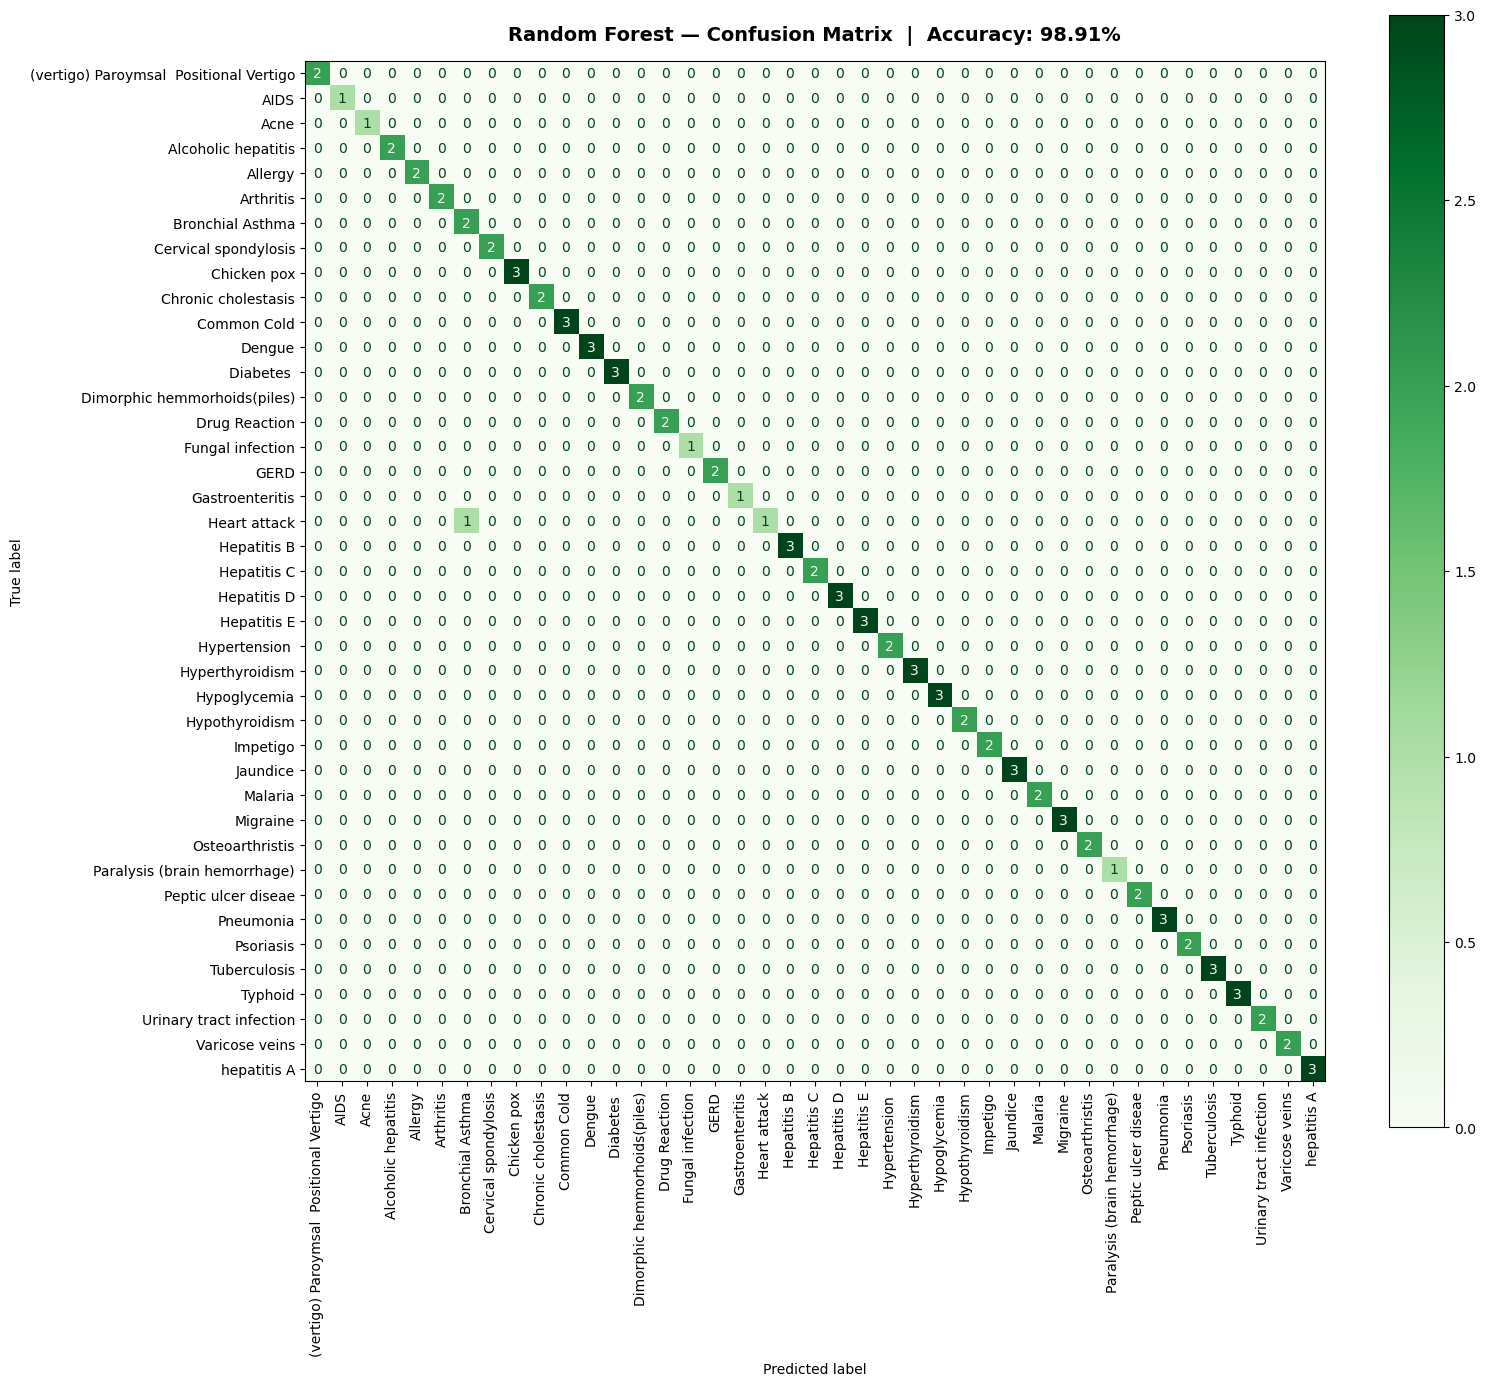

In [24]:
fig, ax = plt.subplots(figsize=(16, 14))
disp = ConfusionMatrixDisplay(confusion_matrix=rf_cm, display_labels=le.classes_)
disp.plot(ax=ax, xticks_rotation=90, colorbar=True, cmap='Greens')
ax.set_title(f'Random Forest — Confusion Matrix  |  Accuracy: {rf_accuracy*100:.2f}%',
             fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()


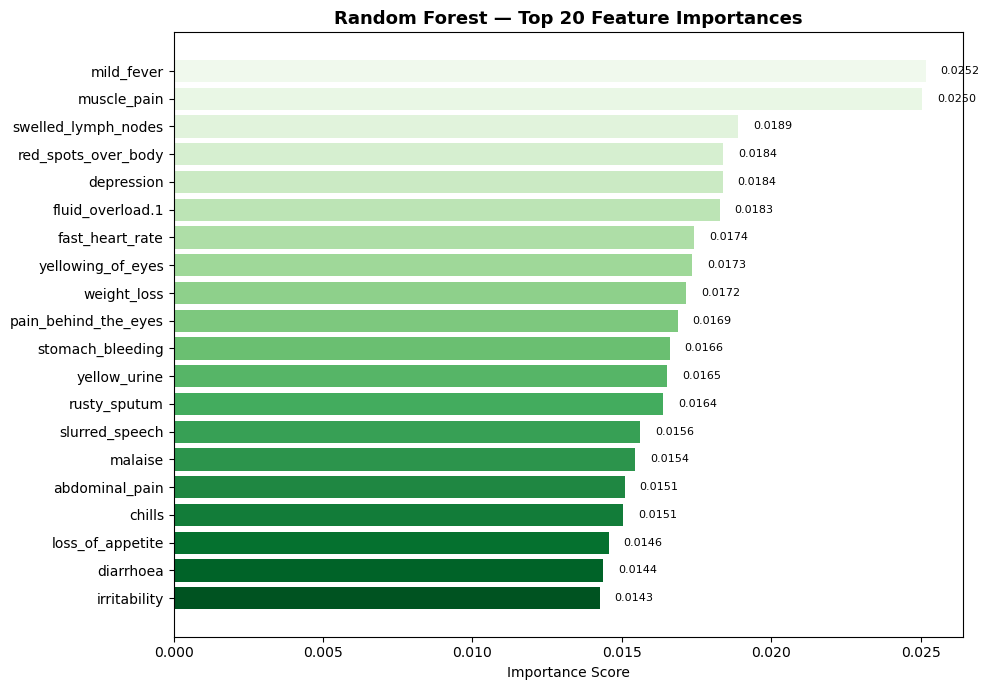

In [25]:
importances = pd.Series(rf_model.feature_importances_, index=X.columns)
top20 = importances.sort_values(ascending=False).head(20)

plt.figure(figsize=(10, 7))
bars = plt.barh(top20.index[::-1], top20.values[::-1],
                color=sns.color_palette('Greens_r', 20))
plt.title('Random Forest — Top 20 Feature Importances', fontweight='bold', fontsize=13)
plt.xlabel('Importance Score')
for bar, val in zip(bars, top20.values[::-1]):
    plt.text(bar.get_width() + 0.0005, bar.get_y() + bar.get_height()/2,
             f'{val:.4f}', va='center', fontsize=8)
plt.tight_layout()
plt.show()


In [26]:
# empty

In [27]:
# ════════════════════════════════════════════════════════════
# MODEL 3 — Gradient Boosting Classifier
# max_depth=3    → shallow trees → slower to overfit
# learning_rate=0.1 → conservative step size
# n_estimators=100  → enough trees to learn but not overfit
# ════════════════════════════════════════════════════════════
gb_model = GradientBoostingClassifier(
    n_estimators=100,
    max_depth=3,            # ← key constraint
    learning_rate=0.1,
    random_state=42
)

gb_model.fit(X_train, y_train)
gb_pred     = gb_model.predict(X_test)
gb_accuracy = accuracy_score(y_test, gb_pred)
gb_cm       = confusion_matrix(y_test, gb_pred)

print('=' * 55)
print('     MODEL 3 — Gradient Boosting Classifier')
print('=' * 55)
print(f'n_estimators     : 100')
print(f'max_depth        : 3')
print(f'learning_rate    : 0.1')
print(f'Accuracy         : {gb_accuracy * 100:.2f}%')
print('\nConfusion Matrix :')
print(np.array2string(gb_cm, separator=','))
print('\nClassification Report:')
print(classification_report(y_test, gb_pred, target_names=le.classes_))


     MODEL 3 — Gradient Boosting Classifier
n_estimators     : 100
max_depth        : 3
learning_rate    : 0.1
Accuracy         : 89.13%

Confusion Matrix :
[[2,0,0,...,0,0,0],
 [0,0,0,...,0,0,0],
 [0,0,0,...,0,0,0],
 ...,
 [0,0,0,...,1,0,0],
 [0,0,0,...,0,2,0],
 [0,0,0,...,0,0,3]]

Classification Report:
                                         precision    recall  f1-score   support

(vertigo) Paroymsal  Positional Vertigo       1.00      1.00      1.00         2
                                   AIDS       0.00      0.00      0.00         1
                                   Acne       0.00      0.00      0.00         1
                    Alcoholic hepatitis       1.00      0.50      0.67         2
                                Allergy       1.00      0.50      0.67         2
                              Arthritis       1.00      0.50      0.67         2
                       Bronchial Asthma       1.00      1.00      1.00         2
                   Cervical spondylosis     

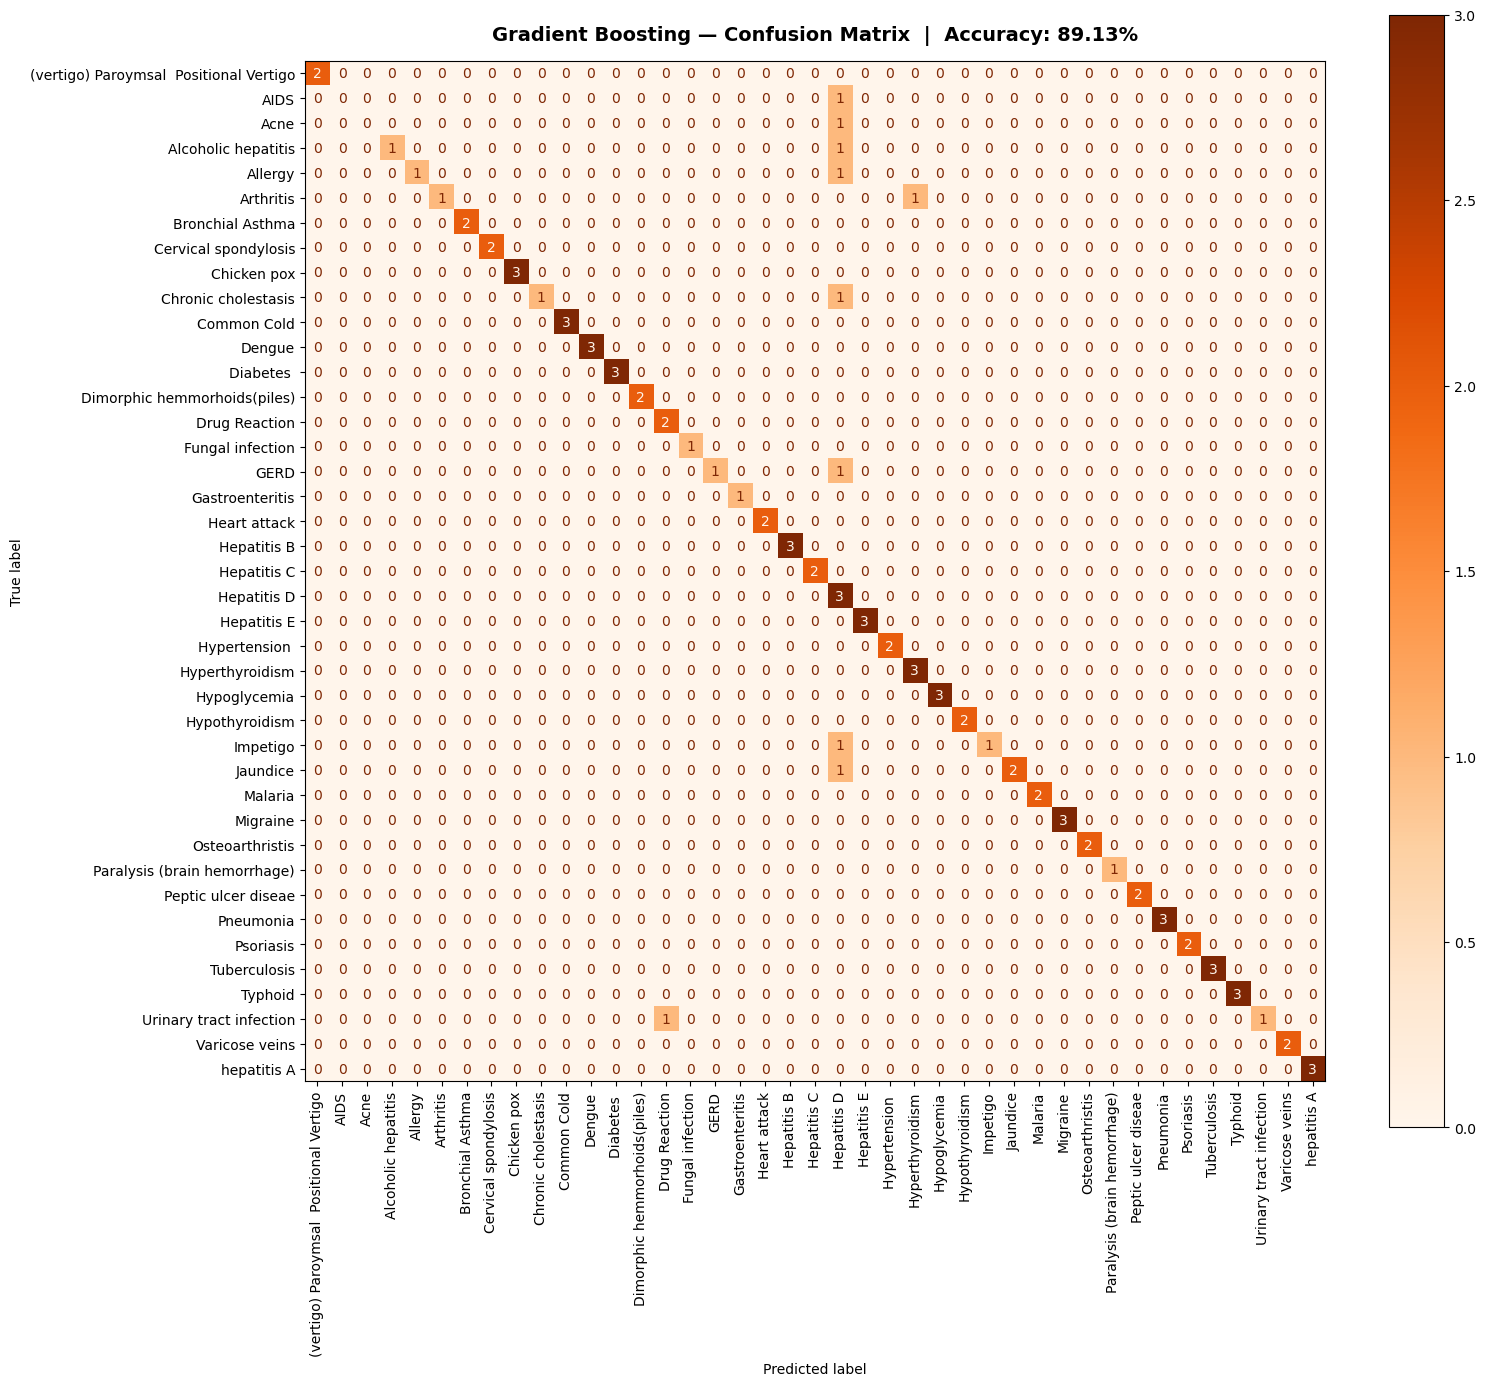

In [28]:
fig, ax = plt.subplots(figsize=(16, 14))
disp = ConfusionMatrixDisplay(confusion_matrix=gb_cm, display_labels=le.classes_)
disp.plot(ax=ax, xticks_rotation=90, colorbar=True, cmap='Oranges')
ax.set_title(f'Gradient Boosting — Confusion Matrix  |  Accuracy: {gb_accuracy*100:.2f}%',
             fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()


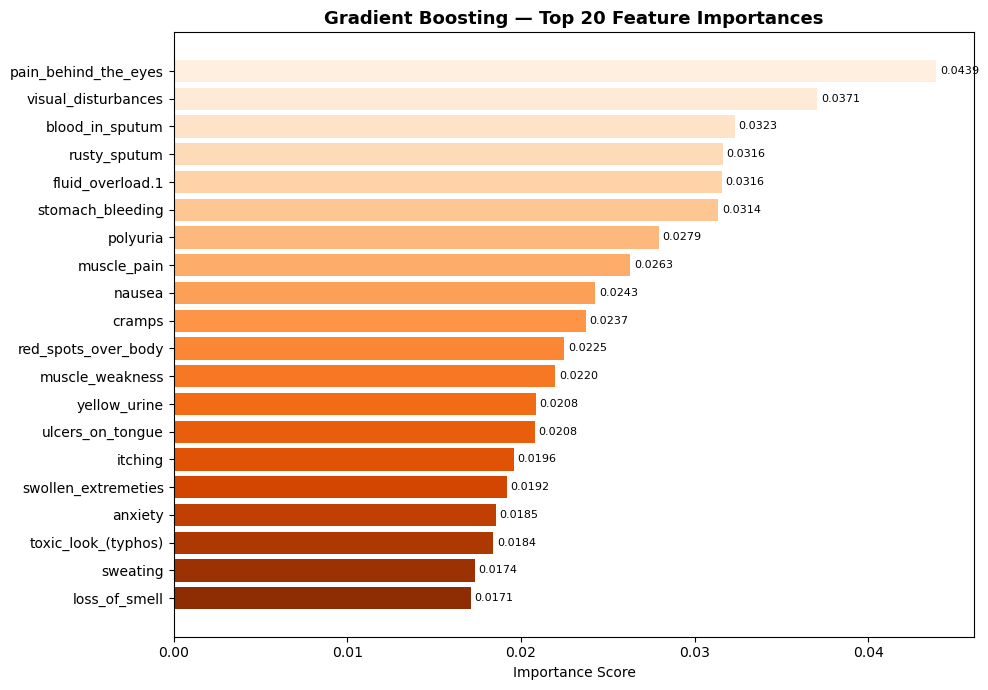

In [29]:
gb_importances = pd.Series(gb_model.feature_importances_, index=X.columns)
gb_top20 = gb_importances.sort_values(ascending=False).head(20)

plt.figure(figsize=(10, 7))
bars = plt.barh(gb_top20.index[::-1], gb_top20.values[::-1],
                color=sns.color_palette('Oranges_r', 20))
plt.title('Gradient Boosting — Top 20 Feature Importances', fontweight='bold', fontsize=13)
plt.xlabel('Importance Score')
for bar, val in zip(bars, gb_top20.values[::-1]):
    plt.text(bar.get_width() + 0.0002, bar.get_y() + bar.get_height()/2,
             f'{val:.4f}', va='center', fontsize=8)
plt.tight_layout()
plt.show()


In [30]:
# empty

In [31]:
# ════════════════════════════════════════════════════════════
# MODEL 4 — K-Nearest Neighbours
# n_neighbors=7 → more neighbours = smoother, less overfit
# weights='distance' → closer neighbours vote more strongly
# ════════════════════════════════════════════════════════════
knn_model = KNeighborsClassifier(
    n_neighbors=7,          # ← increased from 5
    weights='distance'      # ← distance-weighted voting
)

knn_model.fit(X_train, y_train)
knn_pred     = knn_model.predict(X_test)
knn_accuracy = accuracy_score(y_test, knn_pred)
knn_cm       = confusion_matrix(y_test, knn_pred)

print('=' * 55)
print('      MODEL 4 — K-Nearest Neighbours (KNN)')
print('=' * 55)
print(f'n_neighbors      : 7')
print(f'weights          : distance')
print(f'Accuracy         : {knn_accuracy * 100:.2f}%')
print('\nConfusion Matrix :')
print(np.array2string(knn_cm, separator=','))
print('\nClassification Report:')
print(classification_report(y_test, knn_pred, target_names=le.classes_))


      MODEL 4 — K-Nearest Neighbours (KNN)
n_neighbors      : 7
weights          : distance
Accuracy         : 100.00%

Confusion Matrix :
[[2,0,0,...,0,0,0],
 [0,1,0,...,0,0,0],
 [0,0,1,...,0,0,0],
 ...,
 [0,0,0,...,2,0,0],
 [0,0,0,...,0,2,0],
 [0,0,0,...,0,0,3]]

Classification Report:
                                         precision    recall  f1-score   support

(vertigo) Paroymsal  Positional Vertigo       1.00      1.00      1.00         2
                                   AIDS       1.00      1.00      1.00         1
                                   Acne       1.00      1.00      1.00         1
                    Alcoholic hepatitis       1.00      1.00      1.00         2
                                Allergy       1.00      1.00      1.00         2
                              Arthritis       1.00      1.00      1.00         2
                       Bronchial Asthma       1.00      1.00      1.00         2
                   Cervical spondylosis       1.00      1.00  

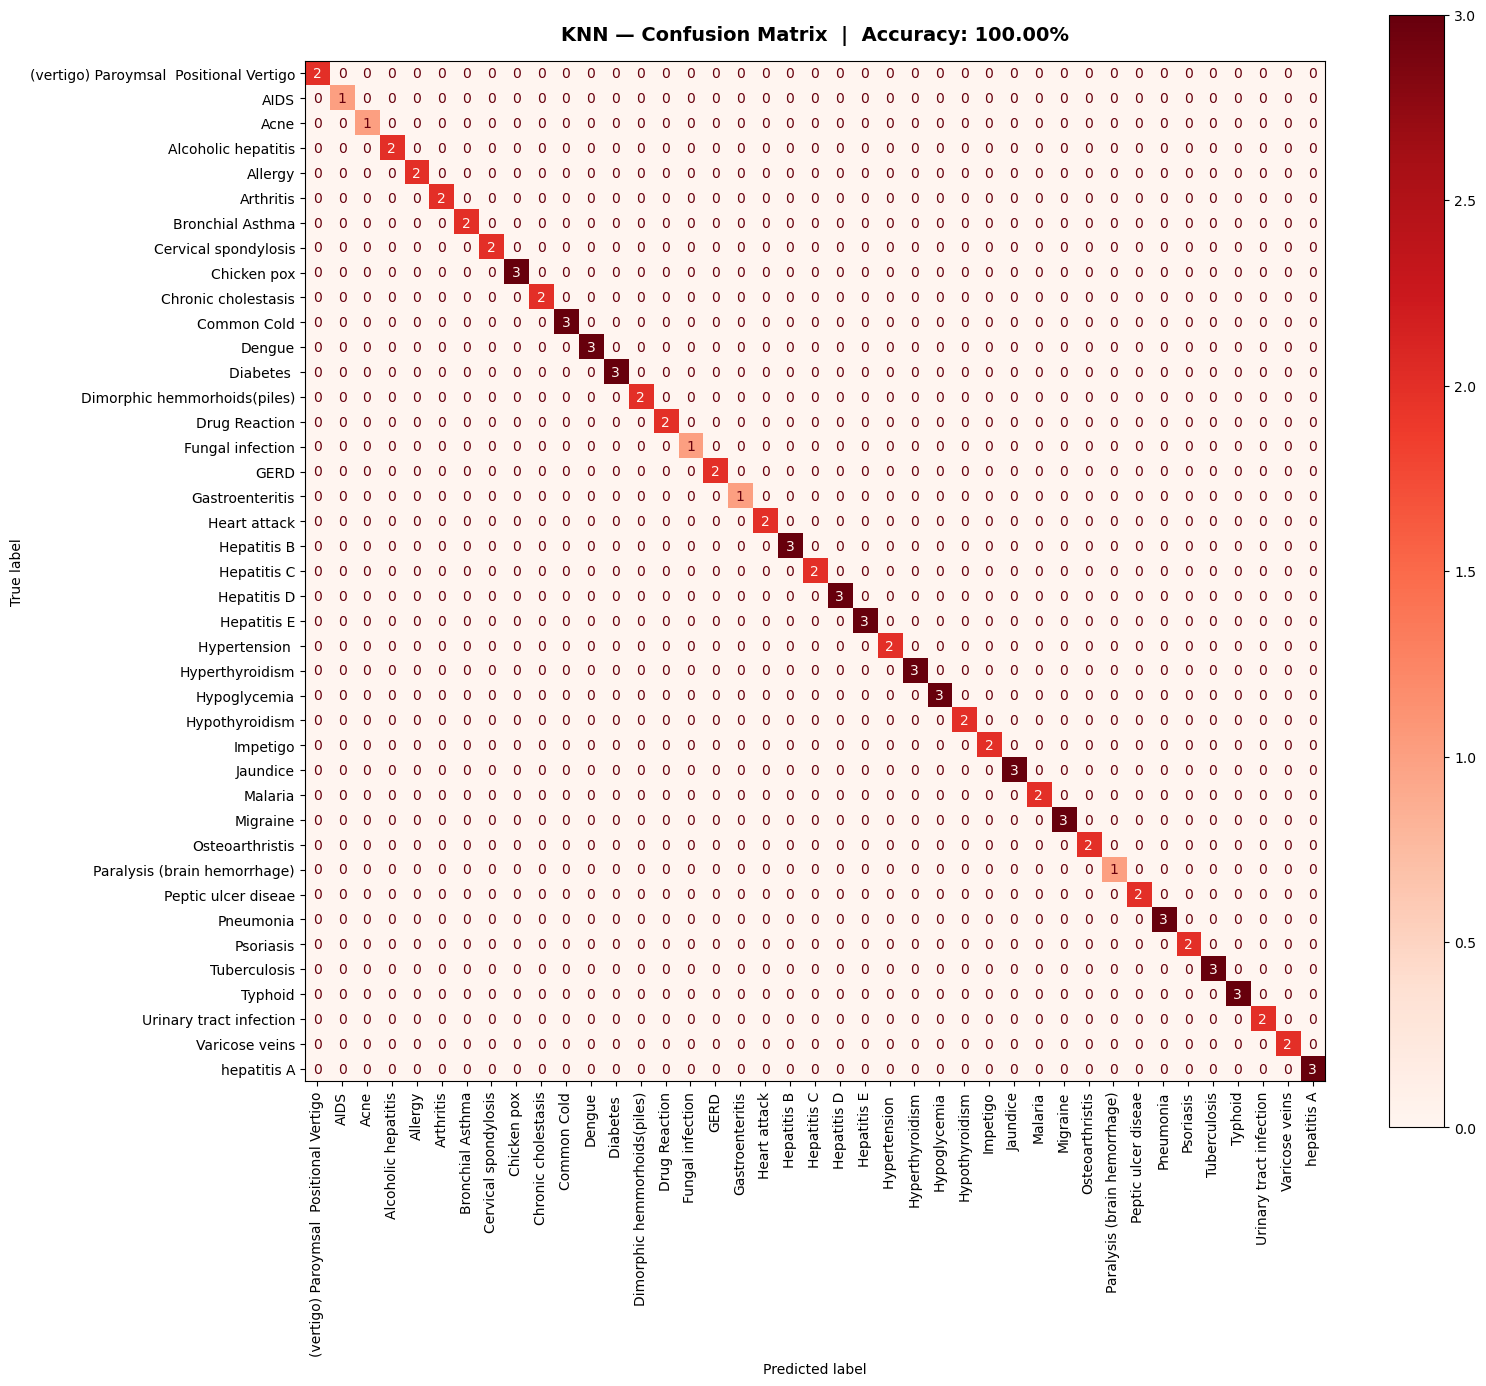

In [32]:
fig, ax = plt.subplots(figsize=(16, 14))
disp = ConfusionMatrixDisplay(confusion_matrix=knn_cm, display_labels=le.classes_)
disp.plot(ax=ax, xticks_rotation=90, colorbar=True, cmap='Reds')
ax.set_title(f'KNN — Confusion Matrix  |  Accuracy: {knn_accuracy*100:.2f}%',
             fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()


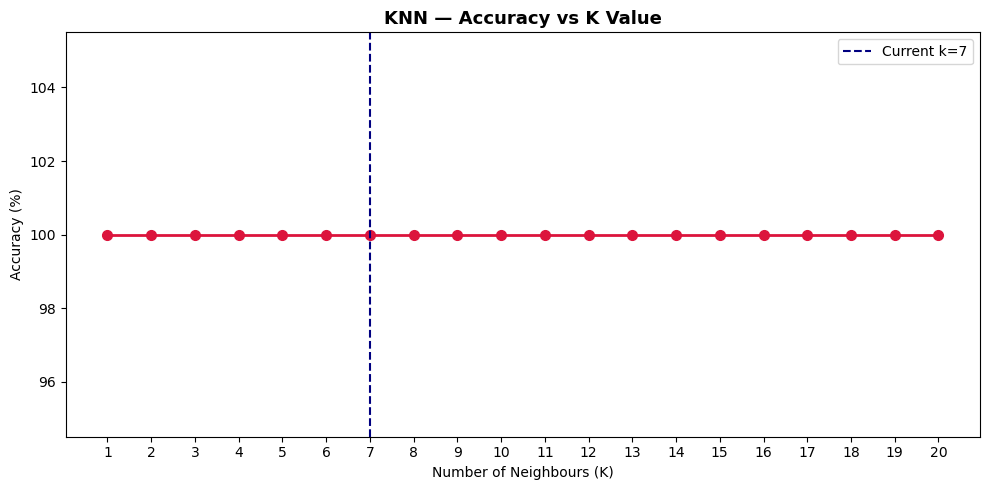

Best K: 1  |  Best Accuracy: 100.00%


In [33]:
# KNN — Find Best K value
k_range = range(1, 21)
k_accuracies = []

for k in k_range:
    knn_k = KNeighborsClassifier(n_neighbors=k, weights='distance')
    knn_k.fit(X_train, y_train)
    k_accuracies.append(accuracy_score(y_test, knn_k.predict(X_test)))

plt.figure(figsize=(10, 5))
plt.plot(k_range, [a*100 for a in k_accuracies], marker='o',
         color='crimson', linewidth=2, markersize=7)
plt.axvline(x=7, color='navy', linestyle='--', label='Current k=7')
plt.title('KNN — Accuracy vs K Value', fontweight='bold', fontsize=13)
plt.xlabel('Number of Neighbours (K)')
plt.ylabel('Accuracy (%)')
plt.xticks(k_range)
plt.legend()
plt.tight_layout()
plt.show()
best_k = list(k_range)[k_accuracies.index(max(k_accuracies))]
print(f'Best K: {best_k}  |  Best Accuracy: {max(k_accuracies)*100:.2f}%')


In [34]:
results = pd.DataFrame({
    'Model'      : ['SVC', 'Random Forest', 'Gradient Boosting', 'KNN'],
    'Accuracy'   : [svc_accuracy, rf_accuracy, gb_accuracy, knn_accuracy],
    'Accuracy %' : [f'{svc_accuracy*100:.2f}%', f'{rf_accuracy*100:.2f}%',
                    f'{gb_accuracy*100:.2f}%',  f'{knn_accuracy*100:.2f}%']
})
results_sorted = results.sort_values('Accuracy', ascending=False).reset_index(drop=True)
results_sorted.index += 1

print('=' * 45)
print('    MODEL COMPARISON — FINAL RESULTS')
print('=' * 45)
print(results_sorted[['Model', 'Accuracy %']].to_string())
print('=' * 45)
print(f'Best Model: {results_sorted.iloc[0]["Model"]} ({results_sorted.iloc[0]["Accuracy %"]})')


    MODEL COMPARISON — FINAL RESULTS
               Model Accuracy %
1                SVC    100.00%
2                KNN    100.00%
3      Random Forest     98.91%
4  Gradient Boosting     89.13%
Best Model: SVC (100.00%)


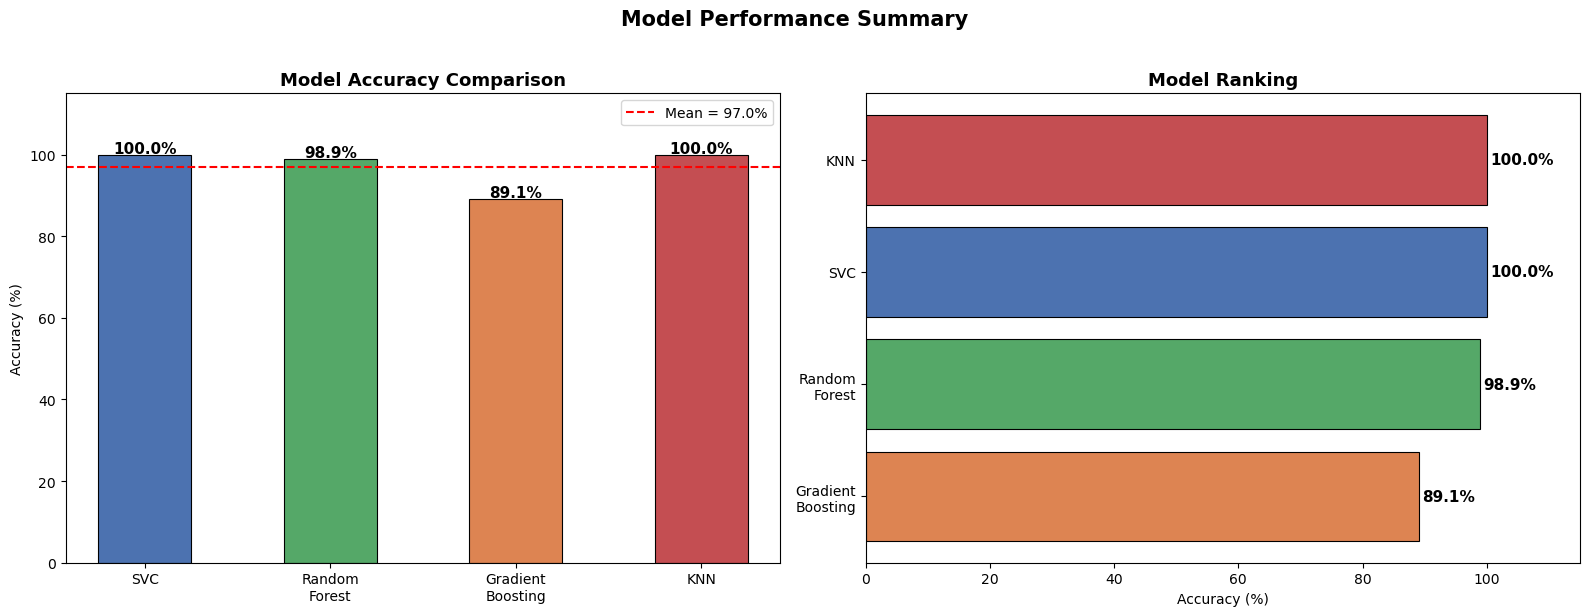

In [35]:
models_list = ['SVC', 'Random\nForest', 'Gradient\nBoosting', 'KNN']
accuracies  = [svc_accuracy, rf_accuracy, gb_accuracy, knn_accuracy]
colors      = ['#4C72B0', '#55A868', '#DD8452', '#C44E52']

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

bars = axes[0].bar(models_list, [a*100 for a in accuracies],
                   color=colors, edgecolor='black', linewidth=0.8, width=0.5)
axes[0].set_ylim(0, 115)
axes[0].set_title('Model Accuracy Comparison', fontweight='bold', fontsize=13)
axes[0].set_ylabel('Accuracy (%)')
axes[0].axhline(y=np.mean(accuracies)*100, color='red', linestyle='--', linewidth=1.5,
                label=f'Mean = {np.mean(accuracies)*100:.1f}%')
for bar, acc in zip(bars, accuracies):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                 f'{acc*100:.1f}%', ha='center', fontweight='bold', fontsize=11)
axes[0].legend()

pairs = sorted(zip(models_list, accuracies, colors), key=lambda x: x[1])
ranked_m, ranked_a, ranked_c = zip(*pairs)
bars2 = axes[1].barh(ranked_m, [a*100 for a in ranked_a],
                     color=ranked_c, edgecolor='black', linewidth=0.8)
axes[1].set_xlim(0, 115)
axes[1].set_title('Model Ranking', fontweight='bold', fontsize=13)
axes[1].set_xlabel('Accuracy (%)')
for bar, acc in zip(bars2, ranked_a):
    axes[1].text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
                 f'{acc*100:.1f}%', va='center', fontweight='bold', fontsize=11)

plt.suptitle('Model Performance Summary', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


In [36]:
# models = {
#     'SVC': SVC(kernel = 'linear'), 
#     'Random_forest' : RandomForestClassifier(n_estimators= 100 , random_state=42),
#     'Gradiant_Boosting': GradientBoostingClassifier(n_estimators=100 , random_state = 42),

#     'Kneighbours': KNeighborsClassifier(n_neighbors= 5 )
# }


# for model_name , model in models.items():
#     model.fit(X_train,y_train)

#     y_pred = model.predict(X_test)

#     accuracy  = accuracy_score(y_test, y_pred )

#     cm = confusion_matrix(y_test , y_pred)

#     print('-=================================================================')
#     print(f"{model_name } accuracy :{accuracy}")
#     print(f"{model_name }  Confusion_matrics : {cm}")
#     print(np.array2string(cm, separator = ",") )

In [37]:
rf = RandomForestClassifier(n_estimators= 100 , random_state=42)
rf.fit(X_train , y_train)
y_pred = rf.predict(X_test)
accuracy = accuracy_score(y_test , y_pred)
accuracy

1.0

In [38]:
svc = SVC(kernel = 'linear')
svc = SVC(kernel = 'linear')
svc.fit(X_train , y_train)
y_pred = svc.predict(X_test)
accuracy = accuracy_score(y_test , y_pred)
accuracy

1.0

In [39]:
import pickle 
pickle.dump(rf , open('model/rf.pkl','wb') )# for RF model 

 
pickle.dump(svc , open('model/svc.pkl','wb') )# for  Svc model 

In [40]:
#load model 
rf = pickle.load(open("model/rf.pkl", 'rb'))
svc = pickle.load(open("model/svc.pkl", 'rb'))

In [41]:
rf

RandomForestClassifier(random_state=42)

In [42]:
X_test.iloc[1].values.reshape(1,-1) # test 1 


array([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]])

In [43]:
rf.predict([[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0]])   # test from Rf 

array([2])

In [44]:
svc.predict([[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0]])

array([2])

In [45]:
X_test.iloc[7].values.reshape(1,-1)  # test 2 

array([[1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1,
        0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0,
        0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]])

In [46]:
rf.predict([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]])

array([5])

In [47]:
y_test 

array([12,  7,  3, 18, 10, 10, 12,  8, 21, 21, 37, 24, 24, 22, 20, 31, 34,
       19, 25,  5,  3, 17, 11, 13, 30, 29,  6, 39,  9, 10, 28, 31,  4, 40,
       25, 26, 34, 37,  4, 12,  8, 36, 28, 30, 14, 25,  7, 40, 21, 33, 38,
       19, 39, 33,  1, 29, 18, 20, 23, 27, 36, 27, 16, 23,  6, 32, 14,  0,
       11, 37,  2, 35,  0, 26,  9, 36, 24, 16, 38,  5, 11, 15, 19, 22,  8,
       34, 40, 28, 22, 30, 35, 13])

MAke Recommendation And Predetion 

In [48]:
#load few data set 

precaution = pd.read_csv("dataset/precautions_df.csv")
workout = pd.read_csv("dataset/workout_df.csv")
medication = pd.read_csv('dataset/medications.csv')
diets = pd.read_csv('dataset/diets.csv')
description = pd.read_csv("dataset/description.csv")


In [49]:
#healper Function 

def helper(dis):
    descr = description[description['Disease'] == dis ]['Description']
    descr = " ".join({ w for w in descr})
    
    pre = precaution[precaution['Disease'] == dis ][['Precaution_1',	'Precaution_2',	'Precaution_3'	,'Precaution_4']]
    pre  = [col for col in pre.values]


    die = diets[diets['Disease']== dis ]['Diet']
    die = [die for die in die.values]
    work = workout[workout['disease']== dis ]['workout']

    med = medication[medication['Disease'] == dis ]['Medication']
    med = [med for med in med.values]

    return descr , pre , die , med, work





symptom_dict = {'itching': 0, 'skin_rash': 1, 'nodal_skin_eruptions': 2, 'continuous_sneezing': 3, 'shivering': 4, 'chills': 5, 'joint_pain': 6, 'stomach_pain': 7, 'acidity': 8, 'ulcers_on_tongue': 9, 'muscle_wasting': 10, 'vomiting': 11, 'burning_micturition': 12, 'spotting_ urination': 13, 'fatigue': 14, 'weight_gain': 15, 'anxiety': 16, 'cold_hands_and_feets': 17, 'mood_swings': 18, 'weight_loss': 19, 'restlessness': 20, 'lethargy': 21, 'patches_in_throat': 22, 'irregular_sugar_level': 23, 'cough': 24, 'high_fever': 25, 'sunken_eyes': 26, 'breathlessness': 27, 'sweating': 28, 'dehydration': 29, 'indigestion': 30, 'headache': 31, 'yellowish_skin': 32, 'dark_urine': 33, 'nausea': 34, 'loss_of_appetite': 35, 'pain_behind_the_eyes': 36, 'back_pain': 37, 'constipation': 38, 'abdominal_pain': 39, 'diarrhoea': 40, 'mild_fever': 41, 'yellow_urine': 42, 'yellowing_of_eyes': 43, 'acute_liver_failure': 44, 'fluid_overload': 45, 'swelling_of_stomach': 46, 'swelled_lymph_nodes': 47, 'malaise': 48, 'blurred_and_distorted_vision': 49, 'phlegm': 50, 'throat_irritation': 51, 'redness_of_eyes': 52, 'sinus_pressure': 53, 'runny_nose': 54, 'congestion': 55, 'chest_pain': 56, 'weakness_in_limbs': 57, 'fast_heart_rate': 58, 'pain_during_bowel_movements': 59, 'pain_in_anal_region': 60, 'bloody_stool': 61, 'irritation_in_anus': 62, 'neck_pain': 63, 'dizziness': 64, 'cramps': 65, 'bruising': 66, 'obesity': 67, 'swollen_legs': 68, 'swollen_blood_vessels': 69, 'puffy_face_and_eyes': 70, 'enlarged_thyroid': 71, 'brittle_nails': 72, 'swollen_extremeties': 73, 'excessive_hunger': 74, 'extra_marital_contacts': 75, 'drying_and_tingling_lips': 76, 'slurred_speech': 77, 'knee_pain': 78, 'hip_joint_pain': 79, 'muscle_weakness': 80, 'stiff_neck': 81, 'swelling_joints': 82, 'movement_stiffness': 83, 'spinning_movements': 84, 'loss_of_balance': 85, 'unsteadiness': 86, 'weakness_of_one_body_side': 87, 'loss_of_smell': 88, 'bladder_discomfort': 89, 'foul_smell_of urine': 90, 'continuous_feel_of_urine': 91, 'passage_of_gases': 92, 'internal_itching': 93, 'toxic_look_(typhos)': 94, 'depression': 95, 'irritability': 96, 'muscle_pain': 97, 'altered_sensorium': 98, 'red_spots_over_body': 99, 'belly_pain': 100, 'abnormal_menstruation': 101, 'dischromic _patches': 102, 'watering_from_eyes': 103, 'increased_appetite': 104, 'polyuria': 105, 'family_history': 106, 'mucoid_sputum': 107, 'rusty_sputum': 108, 'lack_of_concentration': 109, 'visual_disturbances': 110, 'receiving_blood_transfusion': 111, 'receiving_unsterile_injections': 112, 'coma': 113, 'stomach_bleeding': 114, 'distention_of_abdomen': 115, 'history_of_alcohol_consumption': 116, 'fluid_overload.1': 117, 'blood_in_sputum': 118, 'prominent_veins_on_calf': 119, 'palpitations': 120, 'painful_walking': 121, 'pus_filled_pimples': 122, 'blackheads': 123, 'scurring': 124, 'skin_peeling': 125, 'silver_like_dusting': 126, 'small_dents_in_nails': 127, 'inflammatory_nails': 128, 'blister': 129, 'red_sore_around_nose': 130, 'yellow_crust_ooze': 131}

diseases_list = {15: 'Fungal infection', 20: 'Hepatitis C', 22: 'Hepatitis E', 3: 'Alcoholic hepatitis', 36: 'Tuberculosis', 10: 'Common Cold', 34: 'Pneumonia', 13: 'Dimorphic hemmorhoids(piles)', 18: 'Heart attack', 39: 'Varicose veins', 26: 'Hypothyroidism', 24: 'Hyperthyroidism', 25: 'Hypoglycemia', 31: 'Osteoarthristis', 5: 'Arthritis', 0: '(vertigo) Paroymsal  Positional Vertigo', 2: 'Acne', 38: 'Urinary tract infection', 35: 'Psoriasis', 21: 'Hepatitis D', 19: 'Hepatitis B', 4: 'Allergy', 40: 'hepatitis A', 16: 'GERD', 9: 'Chronic cholestasis', 14: 'Drug Reaction', 33: 'Peptic ulcer diseae', 1: 'AIDS', 12: 'Diabetes', 17: 'Gastroenteritis', 6: 'Bronchial Asthma', 23: 'Hypertension', 30: 'Migraine', 7: 'Cervical spondylosis', 32: 'Paralysis (brain hemorrhage)', 28: 'Jaundice', 29: 'Malaria', 8: 'Chicken pox', 11: 'Dengue', 37: 'Typhoid', 27: 'Impetigo'}




#model prediction 

def get_predicted_value(patient_symptoms):
    input_vector = np.zeros(len(symptom_dict))
    for item in patient_symptoms:
        input_vector[symptom_dict[item]] = 1
    return diseases_list[svc.predict([input_vector])[0]]

In [50]:
symptoms = input('Enter Your Symptoms Here..')
user_symptoms = [ s for s in symptoms.split(',')]
user_symptoms = [ sym.strip("[]'") for sym in user_symptoms]

predicted_disease = get_predicted_value(user_symptoms)
descr , pre , die , med, work = helper(predicted_disease)

#Result Time 
print('********************************Predicted Disease ************************************')
print(" Mohit's Machine Prediction is:-", predicted_disease )
print('********************************Predicted Description ************************************')
print(descr)
print('********************************Predicted Precaution ************************************')
i = 1
for j in pre[0]:
    print(i , ':' , j)
    i += 1
print('********************************Predicted Diets ************************************')
for i in die:
    
    print(i)
    
print('********************************Predicted Medication ************************************')
i = 1 
for j in med:
    print(i, ":", j)
    i+= 1 
print('********************************Predicted workout ************************************')
i = 1 
for j in med:
    print(i, ":", j)
    i+= 1 


Enter Your Symptoms Here.. itching


********************************Predicted Disease ************************************
 Mohit's Machine Prediction is:- Fungal infection
********************************Predicted Description ************************************
Fungal infection is a common skin condition caused by fungi.
********************************Predicted Precaution ************************************
1 : bath twice
2 : use detol or neem in bathing water
3 : keep infected area dry
4 : use clean cloths
********************************Predicted Diets ************************************
['Antifungal Diet', 'Probiotics', 'Garlic', 'Coconut oil', 'Turmeric']
********************************Predicted Medication ************************************
1 : ['Antifungal Cream', 'Fluconazole', 'Terbinafine', 'Clotrimazole', 'Ketoconazole']
********************************Predicted workout ************************************
1 : ['Antifungal Cream', 'Fluconazole', 'Terbinafine', 'Clotrimazole', 'Ketoconazole']
